# AP 155 Lab Exercise
---
## Exercise 11: Integration

_Instructions_:
- **Report**: See instructions in Problems 1,2,3
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: De Casa, Samantha Claire E.
- _Student No._: 2023-15141
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

![Description](Figure_1111.png)
**Figure 1.1** 

![Description](Figure_1112.png)
**Figure 1.2**

![Description](Figure_1112.png)
**Figure 1.3**

Figures 1.1, 1.2, and 1.3 reveal the absolute error vs. no. of divisions for the trapezoidal integration and integration via Simpson's rule of $y = \sqrt{9-4x^2}$ with bounds $(x=0, x=3/2)$, $y = -x^2 + 1$ with bounds $(x=-2, x=2)$, and $y = \sqrt{x}\cos{x}$ with bounds $(x=0, x=\pi)$.


![Description](Figure_1121.png)
**Figure 2.1**

![Description](Figure_1122.png)
**Figure 2.2**

![Description](Figure_1123.png)
**Figure 2.3**

Figures 2.1, 2.2, and 2.3 show the Monte Carlo simulation of $y = \sqrt{9-4x^2}$ with bounds $(x=0, x=3/2)$, $y = -x^2 + 1$ with bounds $(x=-2, x=2)$, and $y = \sqrt{x}\cos{x}$ with bounds $(x=0, x=\pi)$.

### Report discussion
1. Trapezoidal integration and integration via Simpson's rule are numerical integration methods used to approximate the definite integrals of a function. Trapezoidal integration approximates the curve using straight line segments so it generally performs well when the function is linear. Increasing the number of intervals generally improves its accuracy, and this is particularly evident in Figures 1.1, 1.2, and 1.3. Integration via Simpson's rule, on the other hand, approximates the area under the curve using parabolic segment so it generally captures curvature better than trapezoidal integration. Generally, Simpson's rule is more accurate than the other when integrating smooth functions using the same number of intervals. However, results from this exercise show that increasing the number intervals does not necessarily guarantee a more accurate result from Simpson's rule. There were still some instances when trapezoidal integration is more accurate. 

2. The reason why Monte Carlo simulation can estimate an integral is that integration can be interpreted as calculating an area, and random sampling allows us to estimate that area statistically. Newton-Cotes methods (such as trapezoidal integration and integration via Simpson's rule), unlike Monte Carlo, use function evaluations at predetermined points. Newton-Cotes methods are generally more appropriate to use when the function is continuous and sufficiently smooth. They are also more suitable when integrating one-dimensional functions because the trapezoidal and Simpson's rule can perform integration using relatively few function evaluations; as opposed to Monte Carlo methods which may require many random samples to achieve comparable accuracy.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

## Problem: 

Given Input:
1. function to integrate
2. bounds
3. number of division/points (for Monte Carlo) 

Make:
1.  a function that can perform Monte Carlo integration
2.  a function that can perform trapezoidal integration
3.  a function that can perform integration via Simpson's Rule (1/3 rule)
4.  a function that can perform integration via Simpson's Rule (3/8 rule)


Output: 
1. total area bounded by the curve, x-axis, and x bounds 
2. signed area (integral)

Make the functions accommodate to any smooth, continuous integrand

Test your functions on the following curves and bounds:

1. $$ y = \sqrt{9-4x^2}, x=0, x=3/2 $$
2. $$ y = -x^2 + 1, x=-2, x=2 $$
3. $$ y = \sqrt{x}\cos{x}, x=0, x=\pi $$

Check your answers (of the integral) with `scipy.integrate.quad`

Report Figures (since there are three functions, there should be a total of 6 figures): 
For each function, plot the following: 

1. Plot the absolute error (relative to the integral computed by scipy) vs the number of divisions/intervals, for each method of integration used. In other words, replicate Figure 7.4 of Gezerlis

2. In the Monte Carlo Simulation, plot the points that are bounded by the curve, the x-axis and the other x- bounds. If the point is above the x-axis, paint it blue, if the point is below the x-axis paint it red. If the area is purely above the x-axis, then all the points should be painted blue.

Report discussion: 
- Explain the figures.
- Why can we arrive at an integration value using Monte Carlo simulation? When are the Newton-Cotes methods more appropriate/suitable than Monte Carlo methods?



In [2]:
def y1(x):
    return np.sqrt(9 - 4*(x**2))

def y2(x): 
    return -(x**2) + 1

def y3(x):
    return np.cos(x)*np.sqrt(x)

In [3]:
sum_y1 = quad(y1, 0, 3/2)
sum_y2 = quad(y2, -2, 2)
sum_y3 = quad(y3, 0, np.pi)

print(sum_y1)
print(sum_y2)
print(sum_y3)

(3.534291735288518, 3.9752112712676535e-10)
(-1.3333333333333335, 4.465845366792915e-14)
(-0.8948314694841447, 5.742084585591556e-11)


In [4]:
def trapezoid(f, a, b, n):
    h = (b - a)/(n - 1)
    xs = a + np.arange(n)*h
    cs = np.ones(n); cs[0] = 0.5; cs[-1] = 0.5
    contribs = cs*f(xs)
    return h*np.sum(contribs)

In [5]:
test_y1 = trapezoid(y1, 0, 3/2, 1000)
test_y2 = trapezoid(y2, -2, 2, 1000)
test_y3 = trapezoid(y3, 0, np.pi, 1000)

print(test_y1, test_y2, test_y3)

3.5342498374451385 -1.3333440213653758 -0.8948683627997766


In [6]:
def simpson(f, a, b, n):
    h = (b - a)/(n - 1)
    xs = a + np.arange(n)*h
    cs = 2*np.ones(n)
    cs[1::2] = 4; cs[0] = 1; cs[-1] = 1
    contribs = cs*f(xs)
    return (h/3)*np.sum(contribs)

In [7]:
test_y1 = simpson(y1, 0, 3/2, 1000)
test_y2 = simpson(y2, -2, 2, 1000)
test_y3 = simpson(y3, 0, np.pi, 1000)

print(test_y1, test_y2, test_y3)

3.5342243029391165 -1.3293400173613719 -0.8929882840684703


/tmp/ipykernel_4775/331100870.py:2: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(9 - 4*(x**2))


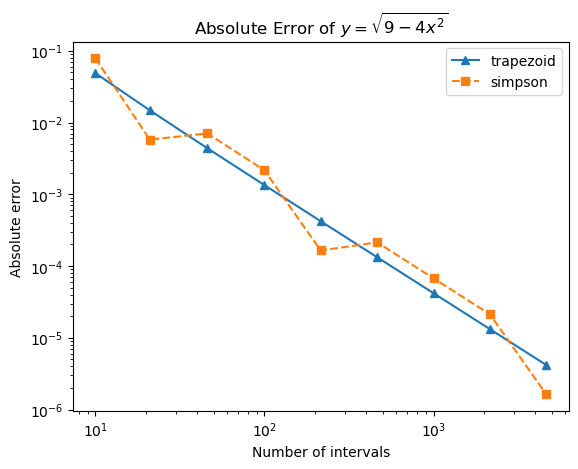

In [18]:
N = np.logspace(1, 4, 10, dtype = np.int_)
y1_tvals = [trapezoid(y1, 0, 3/2, n) for n in N]
y1_svals = [simpson(y1, 0, 3/2, n) for n in N]

trapezoid_errors = [np.abs(sum_y1[0] - i) for i in y1_tvals]
simpson_errors = [np.abs(sum_y1[0] - i) for i in y1_svals]

plt.loglog(N, trapezoid_errors, label = 'trapezoid', linestyle = '-', marker = '^')
plt.loglog(N, simpson_errors, label = 'simpson', linestyle = '--', marker = 's')
plt.title(r'Absolute Error of $y = \sqrt{9-4x^2}$')
plt.xlabel('Number of intervals')
plt.ylabel('Absolute error')
plt.legend()
plt.savefig('Figure_1111.png')
plt.show()

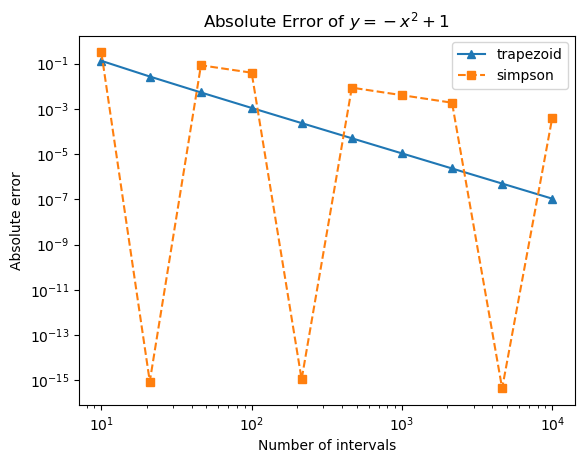

In [19]:
N = np.logspace(1, 4, 10, dtype = np.int_)
y2_tvals = [trapezoid(y2, -2, 2, n) for n in N]
y2_svals = [simpson(y2, -2, 2, n) for n in N]

trapezoid_errors = [np.abs(sum_y2[0] - i) for i in y2_tvals]
simpson_errors = [np.abs(sum_y2[0] - i) for i in y2_svals]
    
plt.loglog(N, trapezoid_errors, label = 'trapezoid',  linestyle = '-', marker = '^')
plt.loglog(N, simpson_errors, label = 'simpson', linestyle = '--', marker = 's')
plt.title(r'Absolute Error of $y = -x^2 + 1$')
plt.xlabel('Number of intervals')
plt.ylabel('Absolute error')
plt.legend()
plt.savefig('Figure_1112.png')
plt.show()

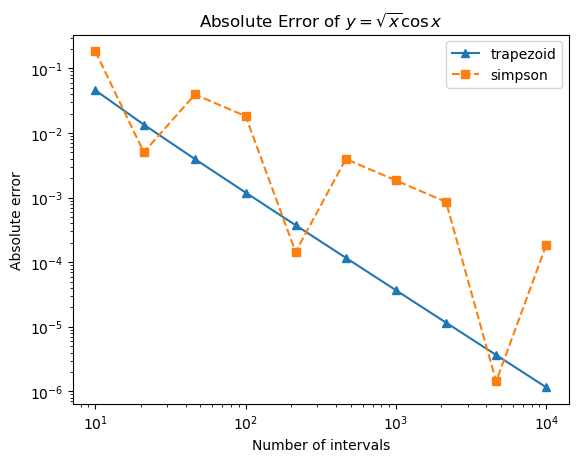

In [20]:
N = np.logspace(1, 4, 10, dtype = np.int_)
y3_tvals = [trapezoid(y3, 0, np.pi, n) for n in N]
y3_svals = [simpson(y3, 0, np.pi, n) for n in N]

trapezoid_errors = [np.abs(sum_y3[0] - i) for i in y3_tvals]
simpson_errors = [np.abs(sum_y3[0] - i) for i in y3_svals]
    
plt.loglog(N, trapezoid_errors, label = 'trapezoid', linestyle = '-', marker = '^')
plt.loglog(N, simpson_errors, label = 'simpson', linestyle = '--', marker = 's')
plt.title(r'Absolute Error of $y = \sqrt{x}\cos{x}$')
plt.xlabel('Number of intervals')
plt.ylabel('Absolute error')
plt.legend()
plt.savefig('Figure_1113.png')
plt.show()

In [11]:
def montecarlo(f, a, b, n, option = "uniform"):
    np.random.seed(314159)
    us = np.random.uniform(a, b, n)

    if option == "uniform":
        fs = f(us)
        
    else:
        c0 = 4 - 2*np.sqrt(2)
        c1 = -6 + 4*np.sqrt(2)
        xs = (-c0 + np.sqrt(2*c1*us + c0**2))/c1
        fs = f(xs)/(c0 + c1*xs)

    fbar, err = stats(fs)
    return (b - a)*fbar, (b - a)*err

def stats(fs):
    n = fs.size
    fbar = np.sum(fs)/n
    fsq = np.sum(fs**2)/n
    varfbar = (fsq - fbar**2)/(n - 1)
    return fbar, np.sqrt(varfbar)

In [12]:
test_y1 = montecarlo(y1, 0, 3/2, 1000)
test_y2 = montecarlo(y2, -2, 2, 1000)
test_y3 = montecarlo(y3, 0, np.pi, 1000)

print(test_y1[0], test_y2[0], test_y3[0])

3.4882505710375478 -1.5884345348731446 -0.9891082212054981


In [13]:
def montecarlo_integration(f, a, b, n):
    x = np.linspace(a, b, n)
    y = f(x)

    y_min = min(0, np.min(y))
    y_max = max(0, np.max(y))

    x_rand = np.random.uniform(a, b, n)
    y_rand = np.random.uniform(y_min, y_max, n)

    y_func = f(x_rand)

    above = (y_rand >= 0) & (y_rand <= y_func)
    below = (y_rand <= 0) & (y_rand >= y_func)

    N_above = np.sum(above)
    N_below = np.sum(below)

    area = (b - a)*(y_max - y_min)
    integral = area * (N_above - N_below)/N

    return x, y, x_rand[above], x_rand[below], y_rand[above], y_rand[below]

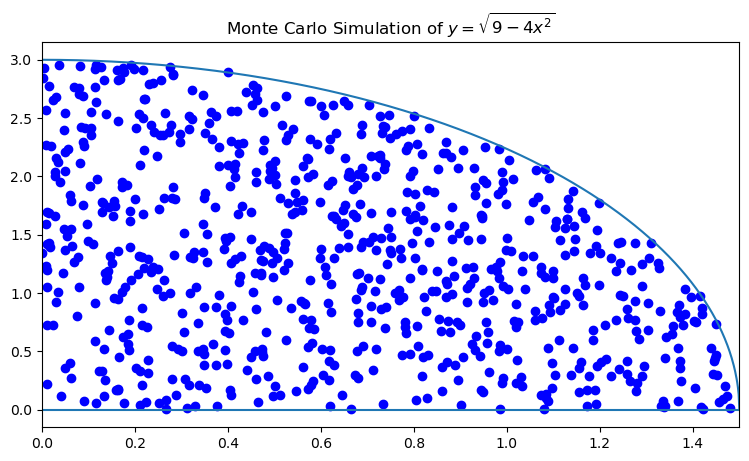

In [14]:
p = montecarlo_integration(y1, 0, 3/2, 1000)

plt.figure(figsize = (9, 5))
plt.title(r'Monte Carlo Simulation of $y = \sqrt{9-4x^2}$')
plt.xlim(0, 3/2)
plt.axhline(0)
plt.plot(p[0], p[1])
plt.scatter(p[2], p[4], color = 'blue')
plt.scatter(p[3], p[5], color = 'red')
plt.savefig('Figure_1121.png')
plt.show()

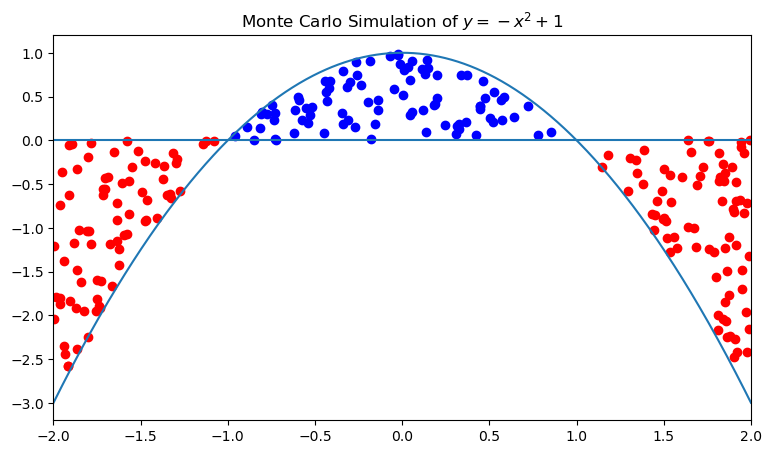

In [15]:
p = montecarlo_integration(y2, -2, 2, 1000)

plt.figure(figsize = (9, 5))
plt.title(r'Monte Carlo Simulation of $y = -x^2 + 1$')
plt.xlim(-2, 2)
plt.axhline(0)
plt.plot(p[0], p[1])
plt.scatter(p[2], p[4], color = 'blue')
plt.scatter(p[3], p[5], color = 'red')
plt.savefig('Figure_1122.png')
plt.show()

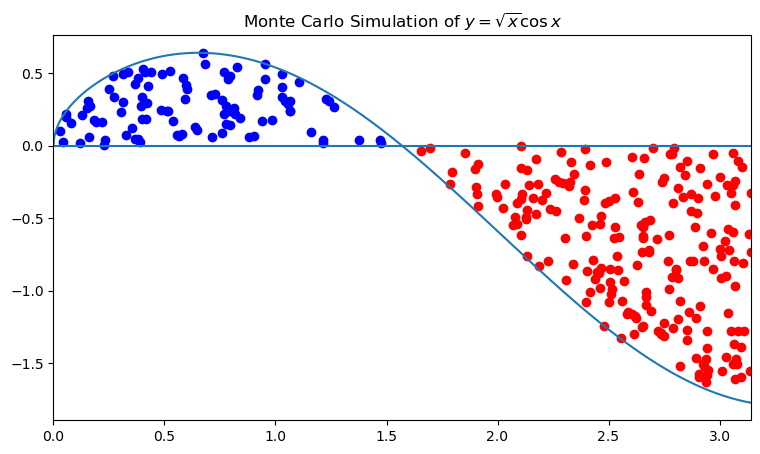

In [16]:
p = montecarlo_integration(y3, 0, np.pi, 1000)

plt.figure(figsize = (9, 5))
plt.title(r'Monte Carlo Simulation of $y = \sqrt{x}\cos{x}$')
plt.xlim(0, np.pi)
plt.axhline(0)
plt.plot(p[0], p[1])
plt.scatter(p[2], p[4], color = 'blue')
plt.scatter(p[3], p[5], color = 'red')
plt.savefig('Figure_1123.png')
plt.show()